# 10. Triangular and Diagonal Forms
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Triangularizing a random complex $8\times 8$ matrix. Left, magnitudes of the entries of $A$. Right, the same operator in a basis (computed by the Schur decomposition, Chapter 14, which even makes the basis orthonormal) where it is upper triangular. The diagonal of the triangular form lists the eigenvalues; below the diagonal everything is zero.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


diagonal of triangular form vs eigenvalues (sorted):
True


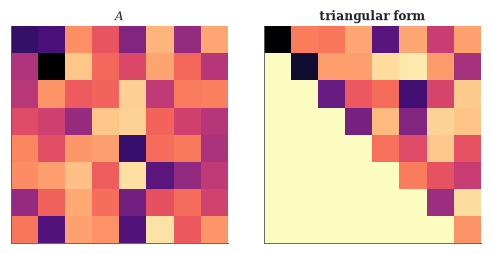

In [2]:
import scipy.linalg as sla
rng = np.random.default_rng(3)
A = rng.normal(size=(8, 8)) + 1j * rng.normal(size=(8, 8))
Tt, Z = sla.schur(A, output="complex")
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
for ax, M, t in [(axs[0], A, "$A$"), (axs[1], Tt, "triangular form")]:
    ax.imshow(np.abs(M), cmap="magma_r", vmin=0); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t)
print("diagonal of triangular form vs eigenvalues (sorted):")
print(np.allclose(np.sort_complex(np.diag(Tt)), np.sort_complex(np.linalg.eigvals(A))))

Diagonalization explains the Fibonacci numbers. Left, the vectors $u_n=(F_n,F_{n+1})$ (dots, log scales) hug the eigenvector line of slope $\varphi$ ever more tightly. Right, the ratio $F_{n+1}/F_n$ converges to $\varphi$, the error shrinking by the factor $\lvert\psi/\varphi\rvert=1/\varphi^2\approx0.38$ per step.

Text(0, 0.5, '$|F_{n+1}/F_n-\\varphi|$')

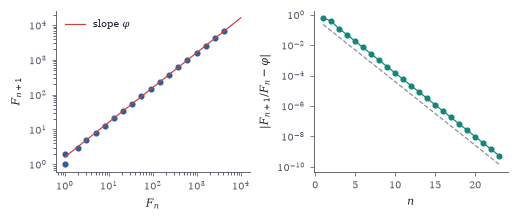

In [3]:
phi, psi = (1 + 5 ** 0.5) / 2, (1 - 5 ** 0.5) / 2
F = [0, 1]
for _ in range(30):
    F.append(F[-1] + F[-2])
F = np.array(F, float)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
axs[0].loglog(F[1:20], F[2:21], "o", color=BLUE, ms=3)
x = np.logspace(0, 4, 2); axs[0].loglog(x, phi * x, color=RED, lw=0.8, label=r"slope $\varphi$")
axs[0].set_xlabel("$F_n$"); axs[0].set_ylabel("$F_{n+1}$"); axs[0].legend()
r = F[2:25] / F[1:24]
axs[1].semilogy(np.arange(1, 24), np.abs(r - phi), "o-", color=TEAL, ms=3, lw=0.8)
axs[1].semilogy(np.arange(1, 24), 0.6 * (1 / phi ** 2) ** np.arange(1, 24), "--", color=GRAY, lw=0.8)
axs[1].set_xlabel("$n$"); axs[1].set_ylabel(r"$|F_{n+1}/F_n-\varphi|$")

Eigenvectors of $A_\varepsilon=\begin{bmatrix}1&1\\0&1+\varepsilon\end{bmatrix}$ merge as $\varepsilon\to 0$. Left, the two eigenvector directions for several $\varepsilon$; the second (coloured) collapses onto the first (black). Right, the condition number of the eigenvector matrix grows like $2/\varepsilon$.

Text(0, 0.5, 'cond$(X)$')

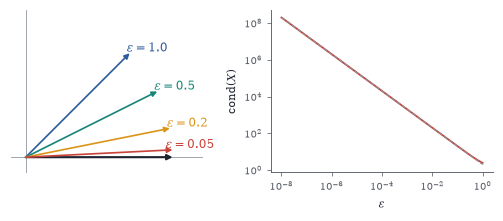

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
ax = plane(axs[0], (-0.1, 1.2, -0.1, 1.0), grid=False)
arrow(ax, (1, 0), color=INK, lw=1.4)
for e, c in zip([1.0, 0.5, 0.2, 0.05], [BLUE, TEAL, GOLD, RED]):
    v = np.array([1, e]) / np.hypot(1, e); arrow(ax, v, color=c, lw=1.1, label=rf"$\varepsilon={e}$", offset=(0.12, 0.03))
eps = np.logspace(-8, 0, 40)
conds = [np.linalg.cond(np.linalg.eig(np.array([[1, 1], [0, 1 + e]]))[1]) for e in eps]
axs[1].loglog(eps, conds, color=RED); axs[1].loglog(eps, 2 / eps, "--", color=GRAY, lw=0.8)
axs[1].set_xlabel(r"$\varepsilon$"); axs[1].set_ylabel("cond$(X)$")

Gershgorin discs (shaded, row version) for a $6\times6$ matrix with dominant diagonal, and its eigenvalues (dots). Every eigenvalue lies in the union of the discs; the isolated disc on the right contains exactly one eigenvalue. Dashed circles, the column-version discs, which give an independent enclosure.

Text(0, 0.5, 'Im')

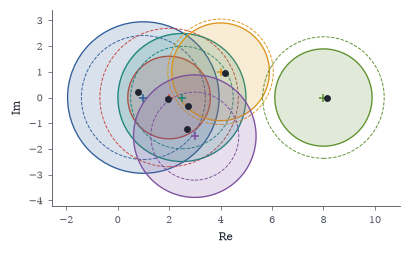

In [5]:
from matplotlib.patches import Circle
rng = np.random.default_rng(6)
A = np.diag([1.0, 2.0, 2.5, 4.0 + 1j, 3.0 - 1.5j, 8.0]) + 0.35 * (rng.normal(size=(6, 6)) + 1j * rng.normal(size=(6, 6))) * (1 - np.eye(6))
lam = np.linalg.eigvals(A)
fig, ax = plt.subplots(figsize=(W, 2.2))
for j in range(6):
    rr = np.abs(A[j]).sum() - abs(A[j, j]); rc = np.abs(A[:, j]).sum() - abs(A[j, j])
    ax.add_patch(Circle((A[j, j].real, A[j, j].imag), rr, color=PALETTE[j], alpha=0.18))
    ax.add_patch(Circle((A[j, j].real, A[j, j].imag), rr, fill=False, ec=PALETTE[j], lw=0.8))
    ax.add_patch(Circle((A[j, j].real, A[j, j].imag), rc, fill=False, ec=PALETTE[j], lw=0.6, ls="--"))
    ax.plot(A[j, j].real, A[j, j].imag, "+", color=PALETTE[j], ms=5)
ax.plot(lam.real, lam.imag, "o", color=INK, ms=3.5)
ax.set_aspect("equal"); ax.autoscale_view(); ax.set_xlabel("Re"); ax.set_ylabel("Im")

Two commuting symmetric matrices $S$ and $T=S^2-2S$ (a polynomial in $S$, so they commute) share their eigenvectors. Each panel shows the image of the unit circle; the principal axes of both ellipses (red) point along the same eigenvectors. A non-commuting pair (right) has misaligned axes.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


ST - TS = 6.661338147750939e-16    SR - RS = 0.72


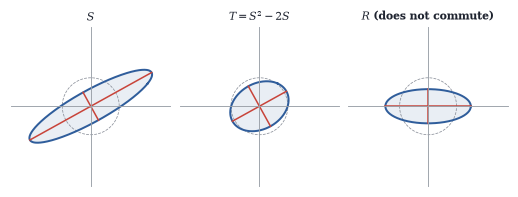

In [6]:
S = np.array([[2.0, 0.8], [0.8, 1.0]]); T = S @ S - 2 * S
R = np.array([[1.5, 0.0], [0.0, 0.6]])
fig, axs = plt.subplots(1, 3, figsize=(W, 1.7))
for ax, M, t in [(axs[0], S, "$S$"), (axs[1], T, "$T=S^2-2S$"), (axs[2], R, "$R$ (does not commute)")]:
    plane(ax, 2.8, grid=False); unit_circle(ax, lw=0.5)
    circle_image(ax, M, color=BLUE, fill=0.1)
    w, V = np.linalg.eigh(M)
    for k in range(2):
        v = V[:, k] * w[k]; ax.plot([-v[0], v[0]], [-v[1], v[1]], color=RED, lw=1)
    ax.set_title(t, fontsize=7)
print("ST - TS =", np.abs(S @ T - T @ S).max(), "   SR - RS =", np.abs(S @ R - R @ S).max().round(3))

In [7]:
phi = (1 + 5 ** 0.5) / 2
F = [0, 1]
for _ in range(40): F.append(F[-1] + F[-2])
print(all(F[n] == round(phi ** n / 5 ** 0.5) for n in range(41)), F[40])

True 102334155


In [8]:
A = np.array([[5, 4], [4, 5.0]]); X = np.array([[1, 1], [1, -1.0]])
R = X @ np.diag([3, 1]) @ np.linalg.inv(X)
print(R, "\nR @ R =\n", R @ R)

[[2. 1.]
 [1. 2.]] 
R @ R =
 [[5. 4.]
 [4. 5.]]


Trajectories of $u'=Au$ for $A=\begin{bmatrix}-1&2\\0&-3\end{bmatrix}$. Every solution decays to the origin; the fast mode along the eigenvector $(1,-1)$ disappears first, so trajectories arrive tangent to the slow eigenvector $(1,0)$ (red lines are the eigenvector directions). The solution from $u(0)=(1,1)$ is drawn in black.

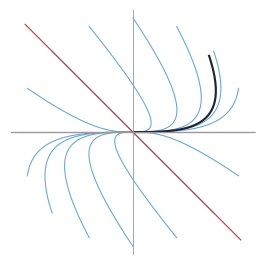

In [9]:
A = np.array([[-1.0, 2.0], [0.0, -3.0]])
lam, X = np.linalg.eig(A); Xi = np.linalg.inv(X)
t = np.linspace(0, 6, 300)
sol = lambda u0: np.array([X @ (np.exp(lam * s) * (Xi @ u0)) for s in t]).real
fig, ax = plt.subplots(figsize=(W * 0.6, 2.3))
plane(ax, 1.6, grid=False)
for th in np.linspace(0, 2 * np.pi, 16, endpoint=False):
    U = sol(1.5 * np.array([np.cos(th), np.sin(th)])); ax.plot(*U.T, color=SKY, lw=0.7)
U = sol(np.array([1.0, 1.0])); ax.plot(*U.T, color=INK, lw=1.4)
for v in X.T:
    v = np.real(v); ax.plot([-2 * v[0], 2 * v[0]], [-2 * v[1], 2 * v[1]], color=RED, lw=0.8)

In [10]:
A = np.array([[10, 1, 0.5], [0.2, 2, 0.3], [0.1, 0.4, 1]])
print(np.sort(np.linalg.eigvals(A).real).round(4))

[ 0.8911  2.0775 10.0315]
